In [1]:
'''
getting a dataframe with wcs coordinates for the inference data
'''

'\n'

In [3]:
import numpy as np

In [5]:
!pip list

Package                 Version
----------------------- -----------
absl-py                 1.3.0
aggdraw                 1.3.19
aiohttp                 3.8.3
aiosignal               1.2.0
anyio                   3.5.0
appdirs                 1.4.4
argon2-cffi             21.3.0
argon2-cffi-bindings    21.2.0
astropy                 5.1
astroquery              0.4.9.post1
asttokens               2.0.5
astunparse              1.6.3
async-timeout           4.0.2
attrs                   22.1.0
Babel                   2.11.0
backcall                0.2.0
backports.tarfile       1.2.0
beautifulsoup4          4.12.2
black                   0.0
bleach                  4.1.0
blinker                 1.4
Bottleneck              1.3.5
brotlipy                0.7.0
cachetools              4.2.2
certifi                 2025.1.31
cffi                    1.15.1
charset-normalizer      2.0.4
click                   8.0.4
cloudpickle             2.2.1
comm                    0.1.2
contourpy            

In [4]:
print(np.__version__)

2.0.0


In [1]:
!pip install numpy==1.23

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 75.1 MB/s eta 0:00:0000:0100:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  error: subprocess-exited-with-error
  
  × Building wheel for numpy (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [1482 lines of output]
      setup.py:71: RuntimeWarning: NumPy 1.23.0 may not yet support Python 3.11.
        warnings.warn(
      Running from numpy source directory.
      setup.py:86: DeprecationWarning:
      
        `numpy.distutils` is deprecated since NumPy 1.23.0, as a result
        of the deprecation of `distutils` itself. It will be removed for
        Python >= 3.12. For older Python versions it will remain present.
        It is recommended to use `setuptools < 60.0` for those Python versions.
        For more details, see:
          https://numpy.org/devdocs/reference/distutils_status_migration.html
      
      


In [1]:
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt
import os
import pandas as pd
from astropy.wcs import WCS
import shutil
from astroquery.gaia import Gaia
from astropy.coordinates import SkyCoord
import astropy.units as u
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
from tensorflow import keras

2025-05-29 15:33:20.241830: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import sys

# adding Folder_2 to the system path
sys.path.insert(0, '/home/3155/rwe')

import review_findings_functions as rff

In [3]:
#matplotlib defaults
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [33]:

fpath_header = "/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/"



In [5]:
df_lessthan13 = pd.read_csv(
    "/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/df_lessthan13"
)

In [12]:
threesig_array = (df_lessthan13['snr_max']>3) | (df_lessthan13['snr_min']<(-3))

In [13]:
df_lessthan13_threesig = df_lessthan13[threesig_array]

In [19]:
np.sum(df_lessthan13_threesig['type']=='both')

50857

In [22]:
np.sum(df_lessthan13_threesig['type']=='pos')+np.sum( df_lessthan13_threesig['type']=='neg')

51093

In [25]:
posneg = (df_lessthan13_threesig['type']=='pos') | (df_lessthan13_threesig['type']=='neg')

In [26]:
df_lessthan13_threesig_posneg = df_lessthan13_threesig[posneg]

In [27]:
df_lessthan13_threesig_posneg

,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio,snr_center,snr_max,snr_min
1,1,1,1,4,4,ztf_20221020297847_000449_zr_c05_x_0006.,pos,655.625000,1208.750000,8.0,4,12.620198,3.551599,3.661652,-3.093721
3,3,3,3,12,12,ztf_20221020297847_000449_zr_c05_x_0006.,pos,2343.333333,1209.500000,12.0,4,9.809223,3.095683,3.140310,-0.995967
4,4,4,4,25,25,ztf_20221020297847_000449_zr_c05_x_0006.,neg,647.000000,1209.928571,14.0,4,12.620198,-1.530615,3.552551,-3.001541
24,24,0,0,3,3,ztf_20221020163819_000640_zg_c01_x_0021.,pos,49.727273,2908.454545,11.0,1,15.091165,2.953927,3.694576,-1.642830
25,25,1,1,28,28,ztf_20221020163819_000640_zg_c01_x_0021.,pos,298.000000,2908.833333,6.0,1,14.822262,-0.201039,0.347701,-3.373438
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
610475,610705,70,70,171,171,ztf_20221020297847_000449_zr_c14_x_0026.,neg,1094.000000,1320.615385,13.0,4,20.657988,0.712186,3.388600,0.263476
610480,610710,75,75,176,176,ztf_20221020297847_000449_zr_c14_x_0026.,neg,1210.300000,1321.400000,20.0,4,14.701658,0.601663,3.700257,0.536696
610509,610739,104,104,231,231,ztf_20221020297847_000449_zr_c14_x_0026.,neg,2124.777778,1320.111111,18.0,4,13.061511,-3.007695,1.359507,-3.470040
610516,610746,111,111,243,243,ztf_20221020297847_000449_zr_c14_x_0026.,neg,2333.500000,1319.714286,14.0,4,12.815176,-2.797584,-1.147434,-3.048873


In [63]:
df = df_lessthan13_threesig_posneg

In [69]:
(df['filename'])[:-6]

1         ztf_20221020297847_000449_zr_c05_x_0006.
3         ztf_20221020297847_000449_zr_c05_x_0006.
4         ztf_20221020297847_000449_zr_c05_x_0006.
24        ztf_20221020163819_000640_zg_c01_x_0021.
25        ztf_20221020163819_000640_zg_c01_x_0021.
                            ...                   
610443    ztf_20221020297847_000449_zr_c14_x_0026.
610446    ztf_20221020297847_000449_zr_c14_x_0026.
610450    ztf_20221020297847_000449_zr_c14_x_0026.
610458    ztf_20221020297847_000449_zr_c14_x_0026.
610464    ztf_20221020297847_000449_zr_c14_x_0026.
Name: filename, Length: 51087, dtype: object

In [75]:
for index, row in df.iterrows():
    if row['filename'][:-6]=='ztf_20221020294271_000449_zr_c09_x' and row['quadrant']==3:
        print('hi')
        #df.drop(row)

hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi
hi


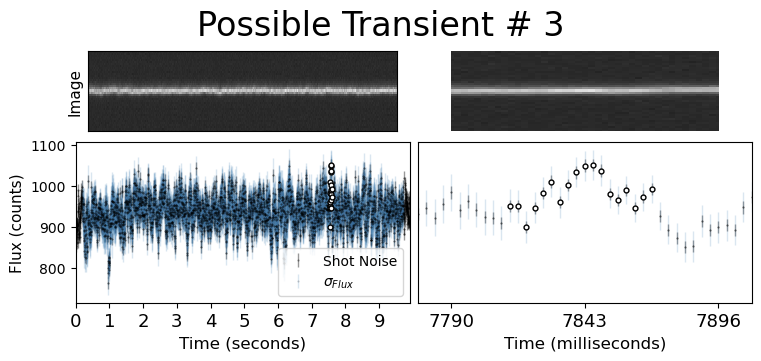

In [44]:
#check that col is the x position: first and second possible transients 
#have same col and are same streak
rff.plot_time_series_again_aperture(df,3) 

In [ ]:
# List to store dictionaries for DataFrame creation
data_list = []

for index, row in df.iterrows():
    image_filename = row['filename']
    print(image_filename[:-6])
    quad = row['quadrant']
    
    xy_file = "/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/" + image_filename[:-6] + "_" + str(quad) + ".fits"
    header_file = fpath_header + image_filename[:-6] + "_" + str(quad) + ".wcs"
    print(header_file)

    try:
        with fits.open(xy_file) as hdul_xy:
            data = hdul_xy[1].data  
            stored_x = data["X"]
            stored_y = data["Y"]
    except Exception as e:
        print(f"Could not open xy_file: {xy_file} — {e}")
        stored_x = stored_y = None

    try:
        with fits.open(header_file) as hdul_header:
            wcs = WCS(hdul_header[0].header, relax=True)
    except Exception as e:
        print(f"Could not open header_file: {header_file} — {e}")
        wcs = None

    if stored_x is not None and stored_y is not None and wcs is not None:
        target_x = row['col_from_nn'] + 10
        closest_idx = np.argmin(np.abs(stored_x - target_x))
        closest_x, closest_y = stored_x[closest_idx], stored_y[closest_idx]
        ra, dec = wcs.all_pix2world(closest_x, closest_y, True)
    else:
        closest_x = closest_y = ra = dec = np.nan

    diff = np.abs(closest_x - (row['col_from_nn'] + 10)) if not np.isnan(closest_x) else np.nan
    data_list.append({**dict(enumerate(row)), 
                      "closest_x": closest_x, 
                      "closest_y": closest_y, 
                      "Diff": diff, 
                      "star_ra": ra, 
                      "star_dec": dec})

ztf_20221020297847_000449_zr_c05_x
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221020297847_000449_zr_c05_x_4.wcs
ztf_20221020297847_000449_zr_c05_x
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221020297847_000449_zr_c05_x_4.wcs
ztf_20221020297847_000449_zr_c05_x
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221020297847_000449_zr_c05_x_4.wcs
ztf_20221020163819_000640_zg_c01_x
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221020163819_000640_zg_c01_x_1.wcs
ztf_20221020163819_000640_zg_c01_x
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221020163819_000640_zg_c01_x_1.wcs
ztf_20221020163819_000640_zg_c01_x
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221020163819_000640_zg_c01_x_1.wcs
ztf_20221020163819_000640_zg_c01_x
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221020163819_000640_zg_c01_x_1.wcs

ztf_20221020163819_000640_zg_c11_x
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221020163819_000640_zg_c11_x_4.wcs
ztf_20221020163819_000640_zg_c11_x
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221020163819_000640_zg_c11_x_4.wcs
ztf_20221020163819_000640_zg_c11_x
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221020163819_000640_zg_c11_x_4.wcs
ztf_20221020163819_000640_zg_c11_x
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221020163819_000640_zg_c11_x_4.wcs
ztf_20221020163819_000640_zg_c11_x
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221020163819_000640_zg_c11_x_4.wcs
ztf_20221020157697_000640_zi_c03_x
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221020157697_000640_zi_c03_x_1.wcs
ztf_20221020157697_000640_zi_c03_x
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221020157697_000640_zi_c03_x_1.wcs

In [61]:
data_list


[{0: 1,
  1: 1,
  2: 1,
  3: 4,
  4: 4,
  5: 'ztf_20221020297847_000449_zr_c05_x_0006.',
  6: 'pos',
  7: 655.625,
  8: 1208.75,
  9: 8.0,
  10: 4,
  11: 12.620198249816896,
  12: 3.551598601905003,
  13: 3.661652464676812,
  14: -3.093720582785101,
  15: 1218.0,
  16: 2209.0,
  17: 0.75,
  18: array(22.62165184),
  19: array(2.9697762),
  'closest_x': nan,
  'closest_y': nan,
  'Diff': nan,
  'star_ra': nan,
  'star_dec': nan}]

ztf_20221020138241_000686_zi_c05_x_0011._2_stamps.npy
2
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c05_x_2.fits
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221020138241_000686_zi_c05_x_2.wcs
ztf_20220820237546_000798_zr_c04_x_0000._4_stamps.npy
4
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20220820237546_000798_zr_c04_x_4.fits
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20220820237546_000798_zr_c04_x_4.wcs
ztf_20221017148750_000831_zi_c03_x_0026._3_stamps.npy
3
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221017148750_000831_zi_c03_x_3.fits
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221017148750_000831_zi_c03_x_3.wcs
ztf_20221020138241_000686_zi_c02_x_0026._1_stamps.npy
1
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c02_x_1.fits
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_h

In [ ]:
# Create DataFrame
df = pd.DataFrame(data_list)

# Display DataFrame structure
df.head()

In [53]:
df_lessthan13_threesig_posneg.head()

,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio,snr_center,snr_max,snr_min
1,1,1,1,4,4,ztf_20221020297847_000449_zr_c05_x_0006.,pos,655.625000,1208.750000,8.0,4,12.620198,3.551599,3.661652,-3.093721
3,3,3,3,12,12,ztf_20221020297847_000449_zr_c05_x_0006.,pos,2343.333333,1209.500000,12.0,4,9.809223,3.095683,3.140310,-0.995967
4,4,4,4,25,25,ztf_20221020297847_000449_zr_c05_x_0006.,neg,647.000000,1209.928571,14.0,4,12.620198,-1.530615,3.552551,-3.001541
24,24,0,0,3,3,ztf_20221020163819_000640_zg_c01_x_0021.,pos,49.727273,2908.454545,11.0,1,15.091165,2.953927,3.694576,-1.642830
25,25,1,1,28,28,ztf_20221020163819_000640_zg_c01_x_0021.,pos,298.000000,2908.833333,6.0,1,14.822262,-0.201039,0.347701,-3.373438


In [ ]:
df.rename(columns={5: 'filename', 
                   6: 'type',
                  7: 'row_from_nn', 
                   8: 'col_from_nn',
                  9:'detection_size',
                  10:'quadrant',
                  11:'sobel_ratio',
                  12:'snr_center',
                  13:'snr_max',
                  14:'snr_min'}, inplace=True)

In [ ]:
df

In [38]:
df.to_csv("/home/3155/inference_star_positions")

In [4]:
inference_df = pd.read_csv("/home/3155/inference_star_info_r12_bands")

In [92]:
howmany = df_r12_diffclean.dropna()

In [93]:
len(inference_df)

51093

In [94]:
len(howmany)

49265

In [1]:
inference_df

NameError: name 'inference_df' is not defined

In [5]:

df_r12_diffclean = inference_df[inference_df["Diff"]<9]

In [81]:
g_stars = df_r12_diffclean[df_r12_diffclean['Band']=="g"]
r_stars = df_r12_diffclean[df_r12_diffclean['Band']=="r"]
i_stars = df_r12_diffclean[df_r12_diffclean['Band']=="i"]



In [82]:
min_ri = min(pd.to_numeric(df_r12_diffclean['rp_mag_ztf_ri'], 'coerce'))

In [83]:
max_ri = max(pd.to_numeric(df_r12_diffclean['rp_mag_ztf_ri'], 'coerce'))

In [32]:
np.l

Signature:
np.linspace(
    start,
    stop,
    num=50,
    endpoint=True,
    retstep=False,
    dtype=None,
    axis=0,
)
Docstring:
Return evenly spaced numbers over a specified interval.

Returns `num` evenly spaced samples, calculated over the
interval [`start`, `stop`].

The endpoint of the interval can optionally be excluded.

.. versionchanged:: 1.16.0
    Non-scalar `start` and `stop` are now supported.

.. versionchanged:: 1.20.0
    Values are rounded towards ``-inf`` instead of ``0`` when an
    integer ``dtype`` is specified. The old behavior can
    still be obtained with ``np.linspace(start, stop, num).astype(int)``

Parameters
----------
start : array_like
    The starting value of the sequence.
stop : array_like
    The end value of the sequence, unless `endpoint` is set to False.
    In that case, the sequence consists of all but the last of ``num + 1``
    evenly spaced samples, so that `stop` is excluded.  Note that the step
    size changes when `endpoint` is Fals

In [33]:
np.arange(min_ri, max_ri+ binwidth, binwidth)

array([ 3.26108456,  4.26108456,  5.26108456,  6.26108456,  7.26108456,
        8.26108456,  9.26108456, 10.26108456, 11.26108456, 12.26108456,
       13.26108456, 14.26108456, 15.26108456, 16.26108456, 17.26108456,
       18.26108456, 19.26108456, 20.26108456])

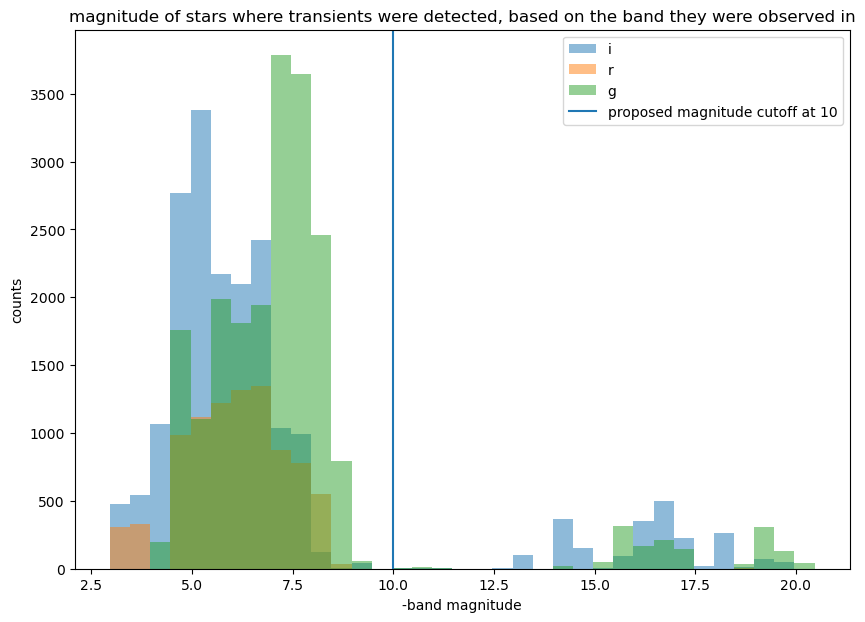

In [86]:
binwidth=.5
plt.hist(pd.to_numeric(i_stars['rp_mag_ztf_ri'], 'coerce'), 
         alpha=.5,label='i', 
         bins=np.arange(min_ri, max_ri+ binwidth, binwidth))
plt.hist(pd.to_numeric(r_stars['rp_mag_ztf_ri'], 'coerce'), alpha=.5,label='r',
         bins=np.arange(min_ri, max_ri+ binwidth, binwidth))
plt.hist(pd.to_numeric(g_stars['bp_mag_ztf_g'], 'coerce'), alpha=.5,label='g',
        bins=np.arange(min_ri, max_ri+ binwidth, binwidth))
plt.title("magnitude of stars where transients were detected, based on the band they were observed in")
plt.ylabel("counts")
plt.xlabel("-band magnitude")
plt.axvline(10, label="proposed magnitude cutoff at 10")
plt.legend()

In [11]:
inference_df

,Unnamed: 0.1,Unnamed: 0,0,1,2,3,4,filename,type,row_from_nn,...,star_ra,star_dec,Band,gaia_source_id,g_mag,bp_rp,rp_mag_ztf_ri,bp_mag_ztf_g,variability,in_vari_summary
0,0,0,1,1,1,4,4,ztf_20221020297847_000449_zr_c05_x_0006.,pos,655.625000,...,22.621652,2.969776,r,2.559791e+18,8.832544,0.59946823,8.453619,9.053087,NOT_AVAILABLE,False
1,1,1,3,3,3,12,12,ztf_20221020297847_000449_zr_c05_x_0006.,pos,2343.333333,...,22.621652,2.969776,r,2.559791e+18,8.832544,0.59946823,8.453619,9.053087,NOT_AVAILABLE,False
2,2,2,4,4,4,25,25,ztf_20221020297847_000449_zr_c05_x_0006.,neg,647.000000,...,22.621652,2.969776,r,2.559791e+18,8.832544,0.59946823,8.453619,9.053087,NOT_AVAILABLE,False
3,3,3,24,0,0,3,3,ztf_20221020163819_000640_zg_c01_x_0021.,pos,49.727273,...,303.875960,23.509883,g,1.830576e+18,4.891197,1.1717238,4.235775,5.407499,NOT_AVAILABLE,False
4,4,4,25,1,1,28,28,ztf_20221020163819_000640_zg_c01_x_0021.,pos,298.000000,...,303.875960,23.509883,g,1.830576e+18,4.891197,1.1717238,4.235775,5.407499,NOT_AVAILABLE,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51088,51088,51088,610705,70,70,171,171,ztf_20221020297847_000449_zr_c14_x_0026.,neg,1094.000000,...,20.736022,7.189586,r,NaN,NaN,NaN,NaN,NaN,NaN,NaN
51089,51089,51089,610710,75,75,176,176,ztf_20221020297847_000449_zr_c14_x_0026.,neg,1210.300000,...,20.736022,7.189586,r,NaN,NaN,NaN,NaN,NaN,NaN,NaN
51090,51090,51090,610739,104,104,231,231,ztf_20221020297847_000449_zr_c14_x_0026.,neg,2124.777778,...,20.736022,7.189586,r,NaN,NaN,NaN,NaN,NaN,NaN,NaN
51091,51091,51091,610746,111,111,243,243,ztf_20221020297847_000449_zr_c14_x_0026.,neg,2333.500000,...,20.736022,7.189586,r,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
len(inference_df)

51093

In [8]:
len(df_r12_nodups)

897

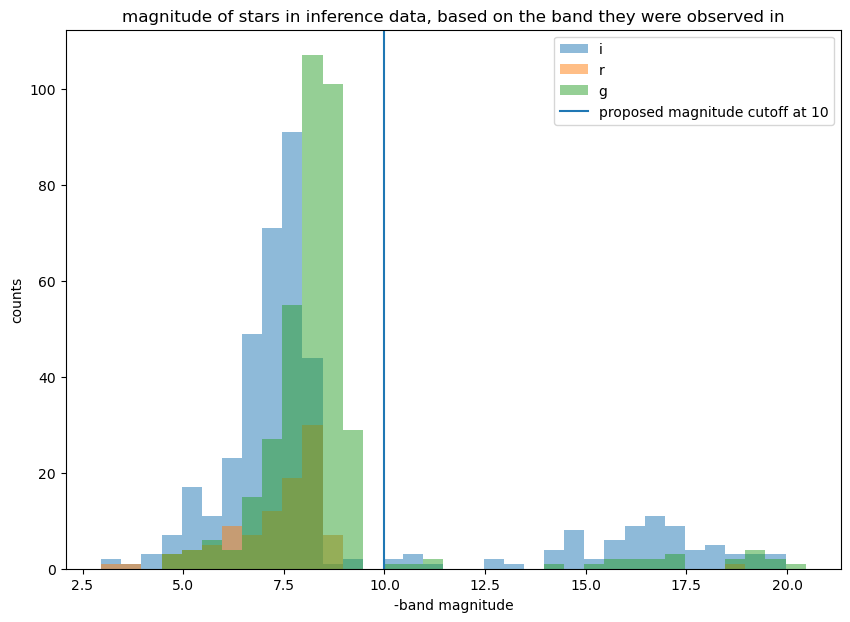

In [7]:
df_r12_nodups = inference_df.drop_duplicates('gaia_source_id')
df_r12_diffclean = df_r12_nodups[df_r12_nodups["Diff"]<9]
g_stars = df_r12_diffclean[df_r12_diffclean['Band']=="g"]
r_stars = df_r12_diffclean[df_r12_diffclean['Band']=="r"]
i_stars = df_r12_diffclean[df_r12_diffclean['Band']=="i"]
min_ri = min(pd.to_numeric(df_r12_diffclean['rp_mag_ztf_ri'], 'coerce'))
max_ri = max(pd.to_numeric(df_r12_diffclean['rp_mag_ztf_ri'], 'coerce'))

binwidth=.5
plt.hist(pd.to_numeric(i_stars['rp_mag_ztf_ri'], 'coerce'), 
         alpha=.5,label='i', 
         bins=np.arange(min_ri, max_ri+ binwidth, binwidth))
plt.hist(pd.to_numeric(r_stars['rp_mag_ztf_ri'], 'coerce'), alpha=.5,label='r',
         bins=np.arange(min_ri, max_ri+ binwidth, binwidth))
plt.hist(pd.to_numeric(g_stars['bp_mag_ztf_g'], 'coerce'), alpha=.5,label='g',
        bins=np.arange(min_ri, max_ri+ binwidth, binwidth))
plt.title("magnitude of stars in inference data, based on the band they were observed in")
plt.ylabel("counts")
plt.xlabel("-band magnitude")
plt.axvline(10, label="proposed magnitude cutoff at 10")
plt.legend()

In [19]:
np.sum(df_r12_diffclean['variability']=='VARIABLE')

126

In [24]:
np.sum(df_r12_diffclean['in_vari_summary']==True)

126

In [25]:
np.sum(inference_df['in_vari_summary']==True)

6731

In [20]:
len(df_r12_diffclean)

880

In [7]:
df_r12_diffclean.columns.values

array(['Unnamed: 0.1', 'Unnamed: 0', '0', '1', '2', '3', '4', 'filename',
       'type', 'row_from_nn', 'col_from_nn', 'detection_size', 'quadrant',
       'sobel_ratio', 'snr_center', 'snr_max', 'snr_min', 'closest_x',
       'closest_y', 'Diff', 'star_ra', 'star_dec', 'Band',
       'gaia_source_id', 'g_mag', 'bp_rp', 'rp_mag_ztf_ri',
       'bp_mag_ztf_g', 'variability', 'in_vari_summary'], dtype=object)

In [22]:
df_r12_diffclean[df_r12_diffclean['in_vari_summary']==True]

,Unnamed: 0.1,Unnamed: 0,0,1,2,3,4,filename,type,row_from_nn,...,star_ra,star_dec,Band,gaia_source_id,g_mag,bp_rp,rp_mag_ztf_ri,bp_mag_ztf_g,variability,in_vari_summary
22,22,22,348,0,0,0,0,ztf_20221020157697_000640_zi_c03_x_0023.,pos,194.050000,...,300.180817,23.800955,i,1.833384e+18,7.440774,-0.18018818,7.543085,7.3628964,VARIABLE,True
72,72,72,1007,3,3,75,75,ztf_20221020141806_000686_zi_c03_x_0025.,pos,1695.818182,...,296.428703,30.258139,i,2.032037e+18,6.243818,2.9805083,4.972851,7.953359,VARIABLE,True
154,154,154,1918,2,2,74,74,ztf_20221020148032_000686_zg_c14_x_0011.,pos,294.000000,...,300.186657,36.590441,g,2.060120e+18,6.739189,-0.10623217,6.754899,6.6486673,VARIABLE,True
182,182,182,2296,11,11,174,174,ztf_20221020157697_000640_zi_c08_x_0023.,pos,787.000000,...,297.549692,24.923464,i,2.020687e+18,7.082869,3.397963,5.761617,9.15958,VARIABLE,True
456,456,456,5743,7,7,20,20,ztf_20221020163819_000640_zg_c15_x_0022.,pos,589.111111,...,299.476826,28.873941,g,2.030005e+18,7.259347,0.2455802,7.089609,7.3351893,VARIABLE,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41638,41638,41638,499761,9,9,561,561,ztf_20221020141806_000686_zi_c12_x_0004.,pos,1758.000000,...,295.968063,33.915165,i,2.047048e+18,13.098408,5.0582685,11.121346,16.179615,VARIABLE,True
42518,42518,42518,509867,109,109,461,461,ztf_20221020141806_000686_zi_c01_x_0020.,pos,1763.727273,...,300.614087,30.072548,i,2.030201e+18,7.688999,2.5638733,6.558457,9.122331,VARIABLE,True
43129,43129,43129,517741,3,3,11,11,ztf_20221020148032_000686_zg_c06_x_0026.,pos,525.500000,...,298.839843,32.740124,g,2.034254e+18,7.964360,0.4131632,7.693117,8.10628,VARIABLE,True
44637,44637,44637,534923,4,4,301,301,ztf_20221020141806_000686_zi_c12_x_0023.,pos,690.000000,...,293.999375,33.419331,i,2.045674e+18,9.574591,3.2067795,8.270483,11.4772625,VARIABLE,True
